# AgriMarket Intelligence — Agricultural Market Price Analysis

This notebook analyzes the current Agmarknet-style market dataset. It covers data cleaning, summary KPIs, commodity and state price comparisons, price spread analysis, and a basic machine-learning model that **estimates modal price from market/commodity categories**.

**Dataset limitation:** a price estimate based on this dataset is not a reliable future-price forecast unless the data contains enough historical dates. The notebook checks date coverage and will state when a time trend cannot be analyzed.

Run the notebook from top to bottom. Keep `data/raw_agmarknet.csv` inside the project's `data` folder.

## 1. Import libraries and load the dataset

In [6]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Works when Jupyter starts in the project root or in the notebooks folder.
# Find the dataset from the project folder
current_dir = Path.cwd().resolve()

search_dirs = [current_dir, *current_dir.parents]

csv_path = None

for folder in search_dirs:
    candidate = folder / "data" / "raw_agmarknet.csv"

    if candidate.is_file():
        csv_path = candidate
        break

if csv_path is None:
    print("Current working directory:", current_dir)
    raise FileNotFoundError(
        "Dataset not found. Check that the data folder contains "
        "raw_agmarknet.csv."
    )

PROJECT_ROOT = csv_path.parent.parent

df_raw = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("File:", csv_path)
print("Rows and columns:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

display(df_raw.head())

Dataset loaded successfully!
File: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\data\raw_agmarknet.csv
Rows and columns: (10580, 10)

Column names:
['State', 'District', 'Market', 'Commodity', 'Variety', 'Grade', 'Arrival_Date', 'Min_x0020_Price', 'Max_x0020_Price', 'Modal_x0020_Price']


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Tripura,Dhalai,Kulai APMC,Bottle gourd,Bottle Gourd,Grade B,20/10/2026,2500.0,3000.0,2800.0
1,Tripura,Dhalai,Kulai APMC,Green Chilli,Green Chilly,Grade B,20/10/2026,24000.0,25000.0,24500.0
2,Andhra Pradesh,Prakasam,Maddipadu APMC,Bajra(Pearl Millet/Cumbu),Bold,FAQ,20/10/2026,2900.0,2900.0,2900.0
3,Andhra Pradesh,Nandyal,Allagadda APMC,Maize,Local,FAQ,20/10/2026,2050.0,2250.0,2150.0
4,Madhya Pradesh,Mandla,Krishi Upaj Mandi Samiti Bichhiya,Green Peas,Pea,FAQ,20/10/2026,3750.0,3750.0,3750.0


## 2. Clean and standardize the market data

The source file uses encoded header names such as `Min_x0020_Price`. This cell renames them to simpler names, parses dates, converts prices to numeric values, removes duplicates, and excludes rows without a valid positive modal price.

In [7]:
df = df_raw.copy()
df.columns = [str(col).strip() for col in df.columns]

# Convert encoded column names into readable names.
rename_map = {
    "Min_x0020_Price": "Min_Price",
    "Max_x0020_Price": "Max_Price",
    "Modal_x0020_Price": "Modal_Price",
    "Min Price": "Min_Price",
    "Max Price": "Max_Price",
    "Modal Price": "Modal_Price",
}
df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns})

required_columns = ["State", "District", "Market", "Commodity", "Arrival_Date", "Modal_Price"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(
        f"The dataset is missing required columns: {missing_columns}. "
        f"Actual columns: {df.columns.tolist()}"
    )

text_columns = ["State", "District", "Market", "Commodity", "Variety", "Grade"]
for col in text_columns:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()
        df[col] = df[col].replace("", pd.NA)

price_columns = ["Min_Price", "Max_Price", "Modal_Price"]
for col in price_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df.loc[df[col] <= 0, col] = np.nan

df["Arrival_Date"] = pd.to_datetime(df["Arrival_Date"], errors="coerce", dayfirst=True)
rows_before = len(df)
duplicate_rows = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
rows_after_duplicates = len(df)
missing_modal_before = int(df["Modal_Price"].isna().sum())
df = df.dropna(subset=["Modal_Price"]).copy()

# Price spread is useful for comparing the range between highest and lowest quotes.
if {"Min_Price", "Max_Price"}.issubset(df.columns):
    df["Price_Spread"] = df["Max_Price"] - df["Min_Price"]
    df.loc[df["Price_Spread"] < 0, "Price_Spread"] = np.nan

df = df.reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Duplicate rows removed:", duplicate_rows)
print("Rows after duplicate removal:", rows_after_duplicates)
print("Rows removed for missing/invalid modal price:", missing_modal_before)
print("Cleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
display(df.isna().sum().rename("Missing values").to_frame())
display(df.head())

Rows before cleaning: 10580
Duplicate rows removed: 0
Rows after duplicate removal: 10580
Rows removed for missing/invalid modal price: 0
Cleaned dataset shape: (10580, 11)

Missing values after cleaning:


,Missing values
State,0
District,0
Market,0
Commodity,0
Variety,0
Grade,0
Arrival_Date,0
Min_Price,0
Max_Price,0
Modal_Price,0


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Price_Spread
0,Tripura,Dhalai,Kulai APMC,Bottle gourd,Bottle Gourd,Grade B,2026-10-20,2500.0,3000.0,2800.0,500.0
1,Tripura,Dhalai,Kulai APMC,Green Chilli,Green Chilly,Grade B,2026-10-20,24000.0,25000.0,24500.0,1000.0
2,Andhra Pradesh,Prakasam,Maddipadu APMC,Bajra(Pearl Millet/Cumbu),Bold,FAQ,2026-10-20,2900.0,2900.0,2900.0,0.0
3,Andhra Pradesh,Nandyal,Allagadda APMC,Maize,Local,FAQ,2026-10-20,2050.0,2250.0,2150.0,200.0
4,Madhya Pradesh,Mandla,Krishi Upaj Mandi Samiti Bichhiya,Green Peas,Pea,FAQ,2026-10-20,3750.0,3750.0,3750.0,0.0


## 3. Understand the dataset

In [8]:
print("Dataset dimensions:", df.shape)
print("\nData types:")
display(df.dtypes.astype(str).rename("Data type").to_frame())

print("\nNumeric summary:")
display(df[[c for c in ["Min_Price", "Max_Price", "Modal_Price", "Price_Spread"] if c in df.columns]].describe().T)

summary_rows = [
    ("Market records", len(df)),
    ("States", df["State"].nunique(dropna=True)),
    ("Districts", df["District"].nunique(dropna=True)),
    ("Markets", df["Market"].nunique(dropna=True)),
    ("Commodities", df["Commodity"].nunique(dropna=True)),
    ("Average modal price (₹/quintal)", round(df["Modal_Price"].mean(), 2)),
    ("Median modal price (₹/quintal)", round(df["Modal_Price"].median(), 2)),
    ("Lowest modal price (₹/quintal)", round(df["Modal_Price"].min(), 2)),
    ("Highest modal price (₹/quintal)", round(df["Modal_Price"].max(), 2)),
]
if df["Arrival_Date"].notna().any():
    summary_rows.extend([
        ("First arrival date", df["Arrival_Date"].min().date()),
        ("Last arrival date", df["Arrival_Date"].max().date()),
        ("Unique arrival dates", df["Arrival_Date"].nunique()),
    ])
display(pd.DataFrame(summary_rows, columns=["Metric", "Value"]))

Dataset dimensions: (10580, 11)

Data types:


,Data type
State,string
District,string
Market,string
Commodity,string
Variety,string
Grade,string
Arrival_Date,datetime64[us]
Min_Price,float64
Max_Price,float64
Modal_Price,float64



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Min_Price,10580.0,4984.606822,6406.685454,0.01,2500.0,3800.0,6000.0,280000.0
Max_Price,10580.0,5648.885454,6848.519738,0.01,2900.0,4000.0,6500.0,280000.0
Modal_Price,10580.0,5318.978889,6597.399827,0.01,2700.0,4000.0,6000.0,280000.0
Price_Spread,10580.0,664.278632,1291.082895,0.00,0.0,500.0,800.0,31251.0


,Metric,Value
0,Market records,10580
1,States,23
2,Districts,322
3,Markets,916
4,Commodities,192
5,Average modal price (₹/quintal),5318.98
6,Median modal price (₹/quintal),4000.0
7,Lowest modal price (₹/quintal),0.01
8,Highest modal price (₹/quintal),280000.0
9,First arrival date,2026-10-20


## 4. Most frequently reported commodities

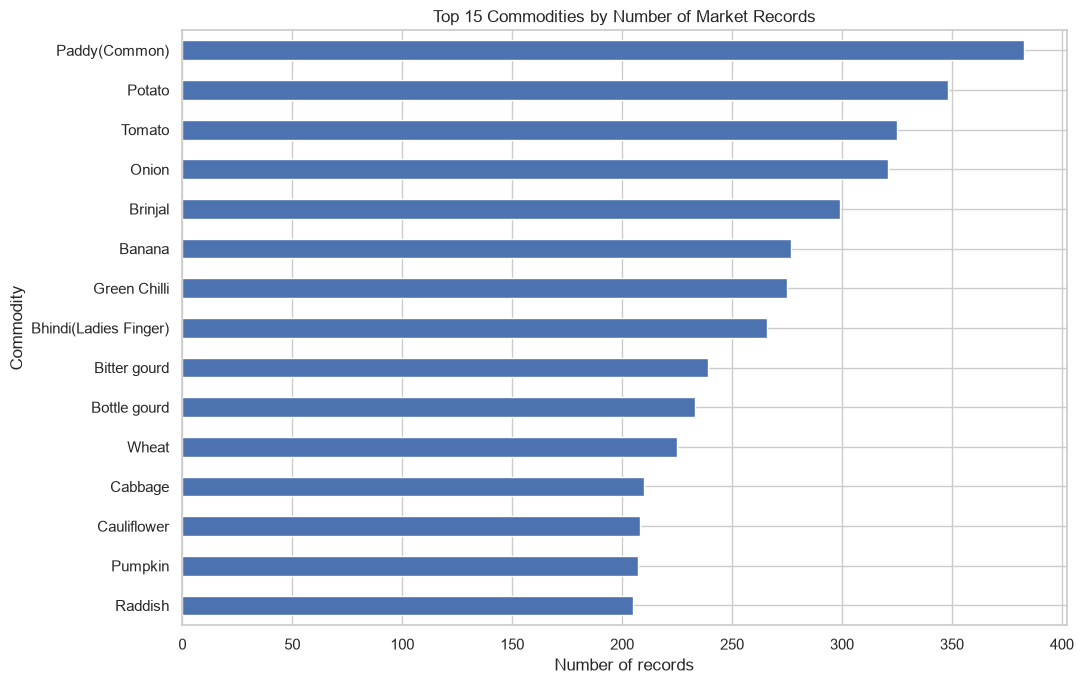

In [9]:
commodity_counts = df["Commodity"].value_counts().head(15).sort_values()
fig, ax = plt.subplots(figsize=(11, 7))
commodity_counts.plot(kind="barh", ax=ax)
ax.set_title("Top 15 Commodities by Number of Market Records")
ax.set_xlabel("Number of records")
ax.set_ylabel("Commodity")
plt.tight_layout()
plt.show()

## 5. Average modal price by commodity

Top commodities by average modal price (₹/quintal):


,Average_Modal_Price,Record_Count
Commodity,,
Mentha Oil,157095.05,6
Tube Flower,148333.33,3
Jasmine,60636.36,11
Walnut,52500.00,4
Kakada,43250.00,4
Makhana(Foxnut),40000.00,1
Ajwan,26335.94,1
Beaten Rice,26000.00,1
Coconut Oil,26000.00,1


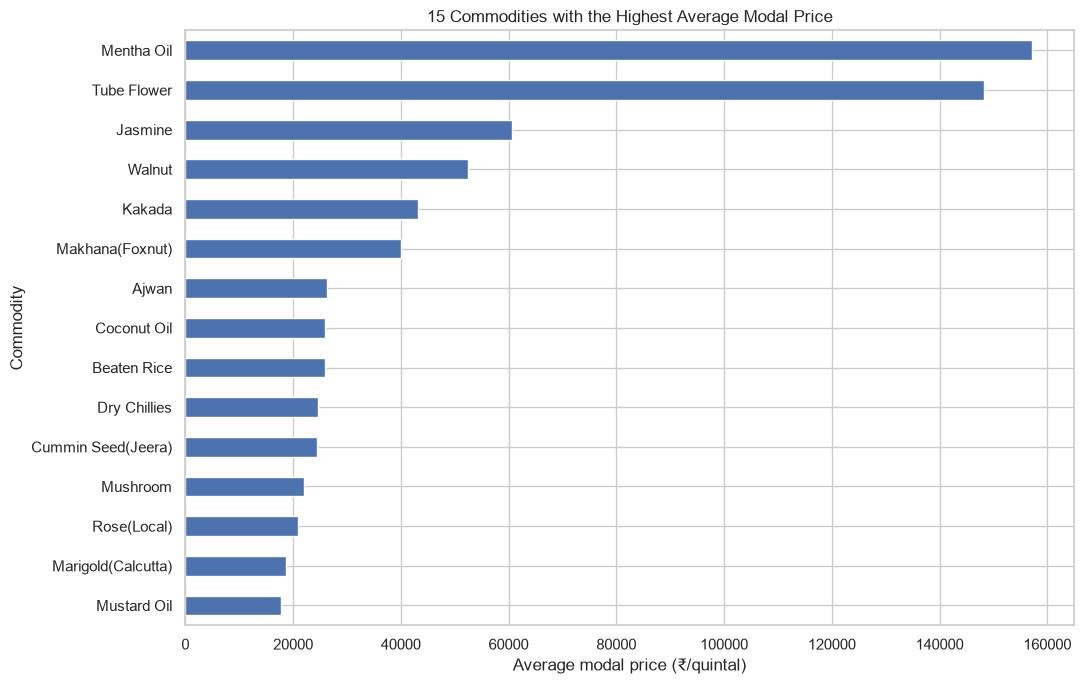

In [10]:
commodity_price = (
    df.groupby("Commodity", dropna=True)["Modal_Price"]
      .agg(Average_Modal_Price="mean", Record_Count="size")
      .sort_values("Average_Modal_Price", ascending=False)
)
print("Top commodities by average modal price (₹/quintal):")
display(commodity_price.head(15).round(2))

plot_data = commodity_price.head(15).sort_values("Average_Modal_Price")
fig, ax = plt.subplots(figsize=(11, 7))
plot_data["Average_Modal_Price"].plot(kind="barh", ax=ax)
ax.set_title("15 Commodities with the Highest Average Modal Price")
ax.set_xlabel("Average modal price (₹/quintal)")
ax.set_ylabel("Commodity")
plt.tight_layout()
plt.show()

## 6. State-wise market price comparison

These averages combine different commodities, so compare them as a broad descriptive summary rather than as a like-for-like price comparison.

States with the highest average modal price across their recorded commodities:


,Average_Modal_Price,Record_Count
State,,
Jammu and Kashmir,52500.00,4
Meghalaya,8000.00,1
Assam,6614.16,75
Tripura,6431.56,61
Tamil Nadu,6085.01,6395
Rajasthan,5692.27,96
Gujarat,5502.18,87
Keralam,5323.85,436
Andhra Pradesh,4882.49,86


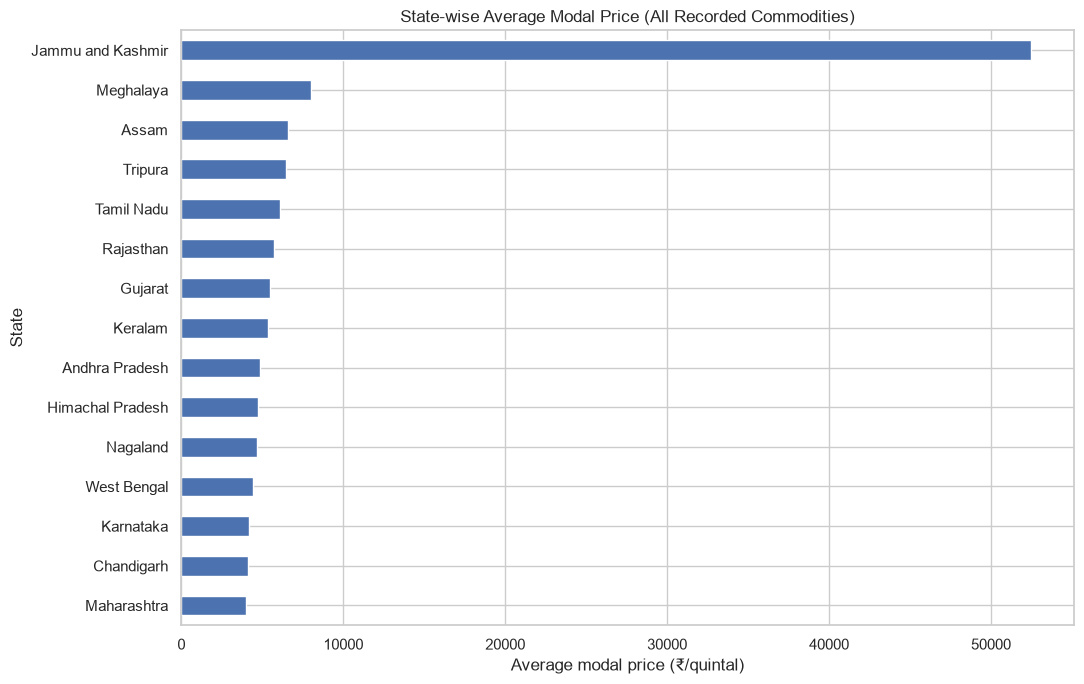

In [11]:
state_price = (
    df.groupby("State", dropna=True)["Modal_Price"]
      .agg(Average_Modal_Price="mean", Record_Count="size")
      .sort_values("Average_Modal_Price", ascending=False)
)
print("States with the highest average modal price across their recorded commodities:")
display(state_price.head(15).round(2))

plot_data = state_price.head(15).sort_values("Average_Modal_Price")
fig, ax = plt.subplots(figsize=(11, 7))
plot_data["Average_Modal_Price"].plot(kind="barh", ax=ax)
ax.set_title("State-wise Average Modal Price (All Recorded Commodities)")
ax.set_xlabel("Average modal price (₹/quintal)")
ax.set_ylabel("State")
plt.tight_layout()
plt.show()

## 7. Distribution of modal prices

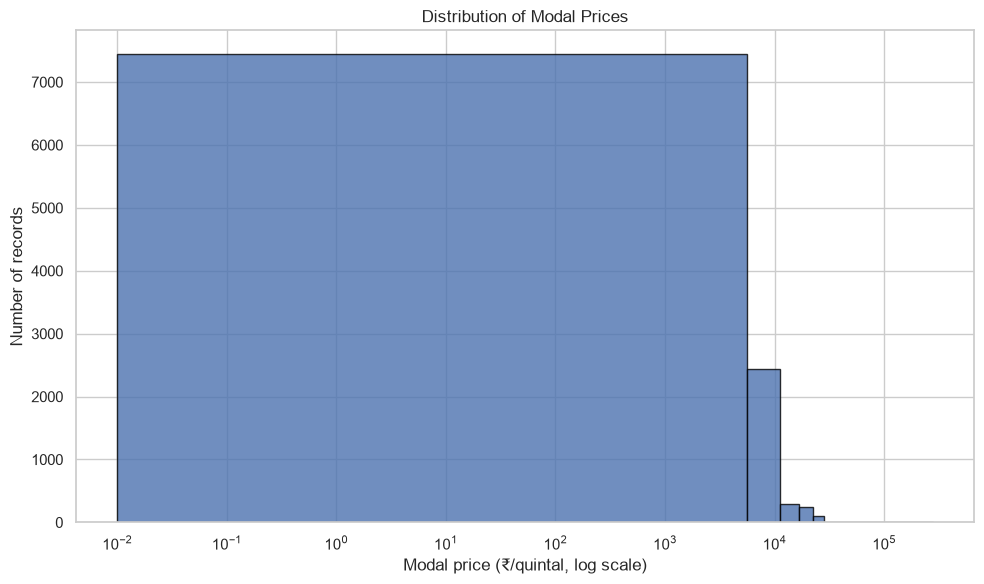

Price percentiles (₹/quintal):


,Modal_Price
0.00,0.01
0.25,2700.00
0.50,4000.00
0.75,6000.00
0.90,9000.00
0.95,14000.00
0.99,23500.00
1.00,280000.00


In [12]:
prices = df["Modal_Price"].dropna()
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(prices, bins=50, edgecolor="black", alpha=0.8)
ax.set_title("Distribution of Modal Prices")
ax.set_xlabel("Modal price (₹/quintal)")
ax.set_ylabel("Number of records")
# A log x-axis helps show both common and high-price commodities when prices are skewed.
if (prices > 0).all() and prices.nunique() > 1:
    ax.set_xscale("log")
    ax.set_xlabel("Modal price (₹/quintal, log scale)")
plt.tight_layout()
plt.show()

print("Price percentiles (₹/quintal):")
display(df["Modal_Price"].quantile([0.00, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00]).rename("Modal_Price").to_frame())

## 8. Minimum, maximum, modal price, and price spread

Commodities with the largest average difference between max and min price:


,Min_Price,Max_Price,Modal_Price,Average_Spread
Commodity,,,,
Walnut,45000.00,60000.00,52500.00,15000.00
Beaten Rice,21600.00,32000.00,26000.00,10400.00
Tube Flower,143333.33,153333.33,148333.33,10000.00
Plum,3000.00,10000.00,6500.00,7000.00
Kakada,40250.00,46250.00,43250.00,6000.00
Cummin Seed(Jeera),21296.19,26649.19,24474.19,5353.00
Persimon(Japani Fal),6500.00,11600.00,8800.00,5100.00
Seetapal,2750.00,7833.33,5400.00,5083.33
Red gram split/Arhar dal/Tur dal,10000.00,15000.00,12500.00,5000.00


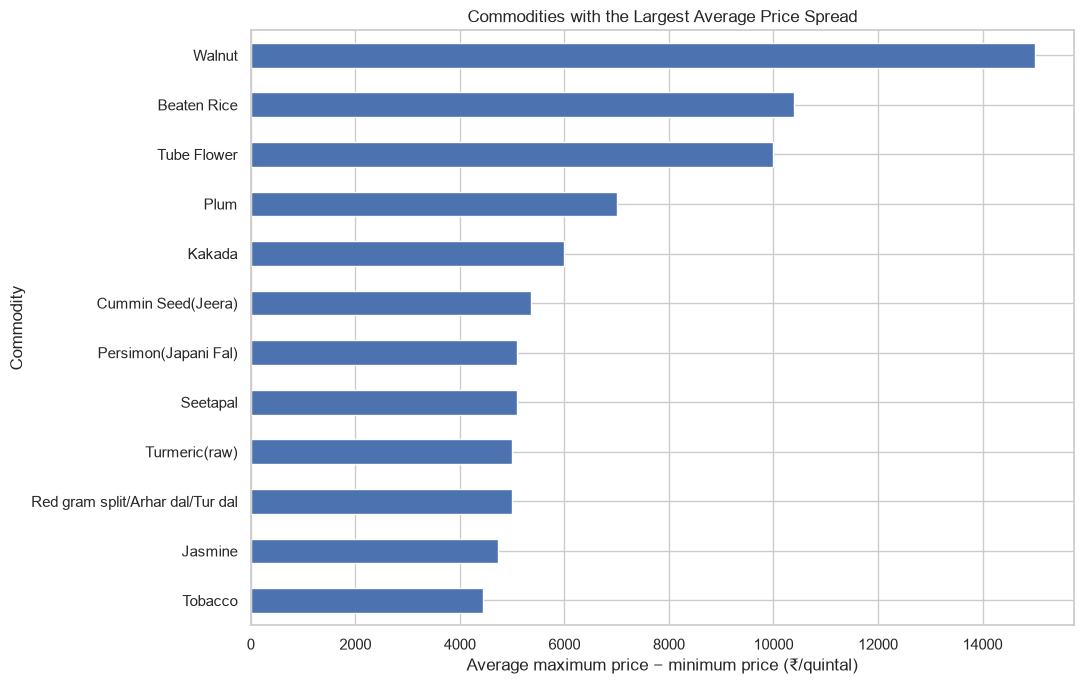

In [13]:
if {"Min_Price", "Max_Price", "Modal_Price"}.issubset(df.columns):
    price_by_commodity = (
        df.groupby("Commodity")[["Min_Price", "Max_Price", "Modal_Price"]]
          .mean(numeric_only=True)
          .dropna(how="all")
    )
    price_by_commodity["Average_Spread"] = price_by_commodity["Max_Price"] - price_by_commodity["Min_Price"]
    price_by_commodity = price_by_commodity.sort_values("Average_Spread", ascending=False)
    print("Commodities with the largest average difference between max and min price:")
    display(price_by_commodity.head(15).round(2))

    plot_data = price_by_commodity.head(12).sort_values("Average_Spread")
    fig, ax = plt.subplots(figsize=(11, 7))
    plot_data["Average_Spread"].plot(kind="barh", ax=ax)
    ax.set_title("Commodities with the Largest Average Price Spread")
    ax.set_xlabel("Average maximum price − minimum price (₹/quintal)")
    ax.set_ylabel("Commodity")
    plt.tight_layout()
    plt.show()
else:
    print("Min_Price or Max_Price is not available, so spread analysis is skipped.")

## 9. Price relationships

Correlation between numeric price fields:


,Min_Price,Max_Price,Modal_Price,Price_Spread
Min_Price,1.000,0.983,0.995,0.253
Max_Price,0.983,1.000,0.995,0.425
Modal_Price,0.995,0.995,1.000,0.338
Price_Spread,0.253,0.425,0.338,1.000


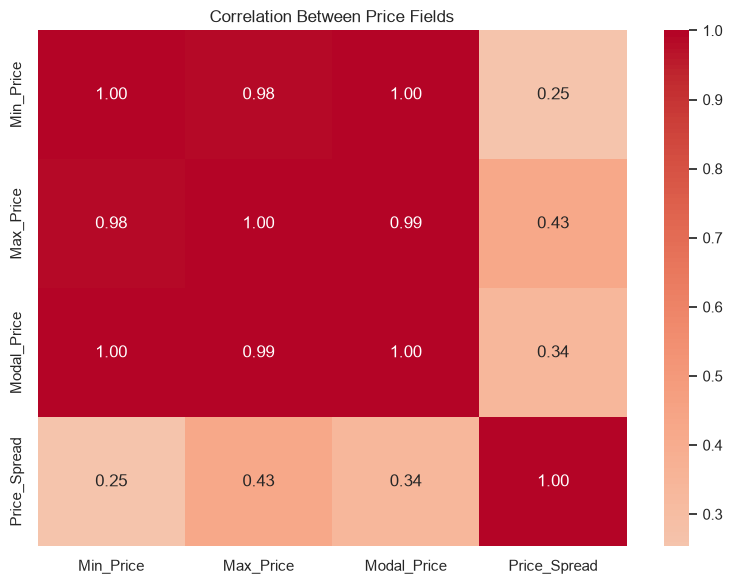

In [14]:
numeric_price_columns = [c for c in ["Min_Price", "Max_Price", "Modal_Price", "Price_Spread"] if c in df.columns]
correlation = df[numeric_price_columns].corr(numeric_only=True)
print("Correlation between numeric price fields:")
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Price Fields")
plt.tight_layout()
plt.show()

## 10. Arrival-date analysis

A true time trend requires multiple distinct arrival dates. If this dataset contains only one date, this cell reports that limitation rather than inventing a trend.

In [15]:
date_data = df.dropna(subset=["Arrival_Date"]).copy()
unique_dates = date_data["Arrival_Date"].nunique()
if unique_dates > 1:
    daily_price = date_data.groupby("Arrival_Date")["Modal_Price"].mean().sort_index()
    fig, ax = plt.subplots(figsize=(12, 5))
    daily_price.plot(ax=ax, marker="o")
    ax.set_title("Average Modal Price by Arrival Date")
    ax.set_xlabel("Arrival date")
    ax.set_ylabel("Average modal price (₹/quintal)")
    plt.tight_layout()
    plt.show()
    print("Distinct arrival dates available:", unique_dates)
else:
    print("Only one or zero distinct arrival dates are available in this dataset.")
    print("A historical price trend or future-price forecast cannot be validated from a single-date snapshot.")
    if unique_dates == 1:
        print("Available date:", date_data["Arrival_Date"].iloc[0].date())

Only one or zero distinct arrival dates are available in this dataset.
A historical price trend or future-price forecast cannot be validated from a single-date snapshot.
Available date: 2026-10-20


## 11. Random Forest model for modal-price estimation

This model estimates modal price using only categorical market and commodity details. It is a baseline model on the available rows, **not a future-market price forecasting model**. For future forecasting, collect historical prices over multiple dates and evaluate using a time-based split.

Random Forest modal-price estimation metrics:


,MAE (₹/quintal),RMSE (₹/quintal),R-squared
0,1118.849,4320.481,0.732


Sample model predictions:


,State,District,Market,Commodity,Variety,Grade,Actual_Modal_Price,Predicted_Modal_Price,Absolute_Error
5359,Tamil Nadu,Nagapattinam,Vedaranyam(Uzhavar Sandhai),Drumstick,Drumstick,Local,3350.0,5946.52,2596.52
9050,Tamil Nadu,Salem,Jalagandapuram(Uzhavar Sandhai ),Papaya,Papaya,Local,3250.0,3314.62,64.62
9607,Tamil Nadu,Vellore,Katpadi (Uzhavar Sandhai ),Groundnut,Big (With Shell),Local,7500.0,7092.61,407.39
8149,Chandigarh,Chandigarh,Chandigarh (Grain/F&V) APMC,Bhindi(Ladies Finger),Bhindi,FAQ,1300.0,2125.06,825.06
4097,Nagaland,Dimapur,Dimapur APMC,Green Chilli,Green Chilly,Small,8000.0,5713.30,2286.70
8718,Tamil Nadu,Madurai,Anna nagar(Uzhavar Sandhai ),Ginger(Green),Green Ginger,Local,19500.0,15224.68,4275.32
5735,Tamil Nadu,Tiruvarur,Mannargudi I(Uzhavar Sandhai ),Chow Chow,Chow Chow,Local,3800.0,4235.15,435.15
469,Tamil Nadu,Tirunelveli,NGO Colony(Uzhavar Sandhai ),Potato,Red Nanital,Local,2400.0,3562.44,1162.44
439,Tamil Nadu,Salem,Thathakapatti(Uzhavar Sandhai ),Mango(Raw-Ripe),Mango - Raw-Ripe,Local,9000.0,8399.69,600.31
9165,Tamil Nadu,Chengalpet,Nanganallur(Uzhavar Sandhai ),Orange,Darjeeling,Local,5750.0,9987.78,4237.78


Most influential encoded features in this fitted model:


,Importance
Commodity_Mentha Oil,0.273969
Variety_Lemon,0.069713
Variety_Garlic,0.051963
Commodity_Jasmine,0.050009
Variety_Tube Flower,0.043020
Commodity_Tube Flower,0.041765
Variety_Jasmine,0.032798
Variety_Green Ginger,0.030898
State_Tamil Nadu,0.022250
Variety_Pomogranate,0.021228


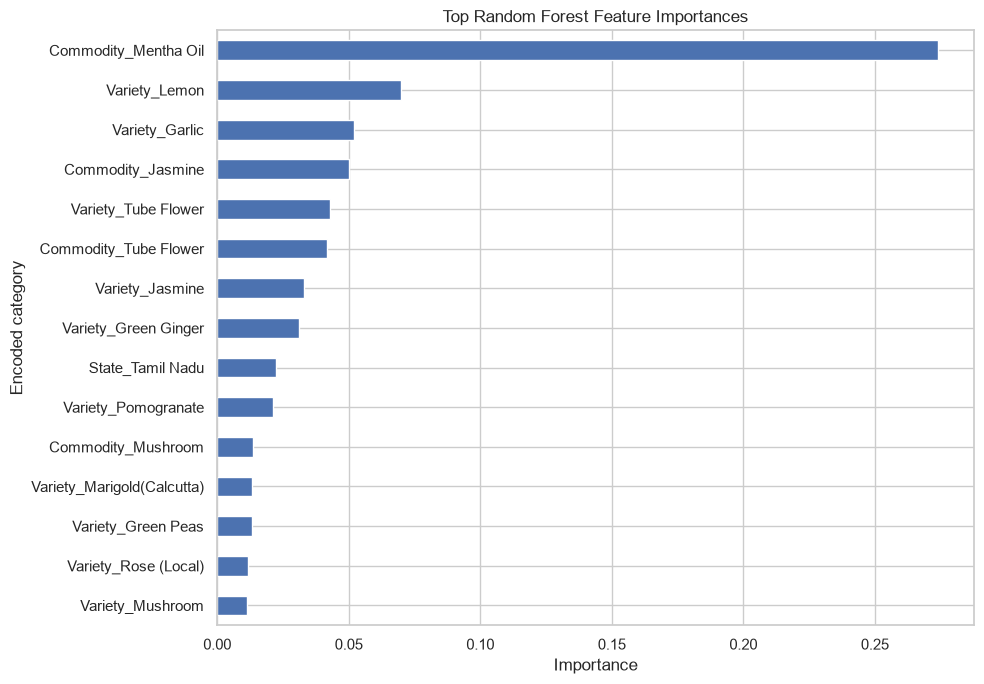

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    col for col in ["State", "District", "Market", "Commodity", "Variety", "Grade"]
    if col in df.columns
]
model_df = df.dropna(subset=["Modal_Price"]).copy()
for col in categorical_features:
    model_df[col] = model_df[col].astype("string").fillna("Unknown").astype(str)

if len(model_df) < 20:
    print("There are fewer than 20 valid rows. More data is needed for a meaningful train/test model.")
else:
    X = model_df[categorical_features]
    y = model_df["Modal_Price"].astype(float)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ],
        remainder="drop",
    )
    price_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            min_samples_leaf=2,
            n_jobs=-1,
        )),
    ])

    price_model.fit(X_train, y_train)
    y_pred = price_model.predict(X_test)
    model_metrics = {
        "MAE (₹/quintal)": mean_absolute_error(y_test, y_pred),
        "RMSE (₹/quintal)": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R-squared": r2_score(y_test, y_pred),
    }
    print("Random Forest modal-price estimation metrics:")
    display(pd.DataFrame([model_metrics]).round(3))

    predictions = X_test.copy()
    predictions["Actual_Modal_Price"] = y_test.values
    predictions["Predicted_Modal_Price"] = y_pred
    predictions["Absolute_Error"] = np.abs(predictions["Actual_Modal_Price"] - predictions["Predicted_Modal_Price"])
    print("Sample model predictions:")
    display(predictions.head(10).round(2))

    encoder = price_model.named_steps["preprocessor"].named_transformers_["categorical"]
    encoded_feature_names = encoder.get_feature_names_out(categorical_features)
    feature_importance = pd.Series(
        price_model.named_steps["regressor"].feature_importances_,
        index=encoded_feature_names,
    ).sort_values(ascending=False)
    print("Most influential encoded features in this fitted model:")
    display(feature_importance.head(15).rename("Importance").to_frame())

    top_features = feature_importance.head(15).sort_values()
    fig, ax = plt.subplots(figsize=(10, 7))
    top_features.plot(kind="barh", ax=ax)
    ax.set_title("Top Random Forest Feature Importances")
    ax.set_xlabel("Importance")
    ax.set_ylabel("Encoded category")
    plt.tight_layout()
    plt.show()

## 12. Key findings generated from this dataset

In [17]:
highest_commodity = df.groupby("Commodity")["Modal_Price"].mean().sort_values(ascending=False)
lowest_commodity = df.groupby("Commodity")["Modal_Price"].mean().sort_values(ascending=True)
highest_state = df.groupby("State")["Modal_Price"].mean().sort_values(ascending=False)

print(f"1. The dataset contains {len(df):,} cleaned market records across {df['State'].nunique()} states, {df['Market'].nunique()} markets, and {df['Commodity'].nunique()} commodities.")
print(f"2. Overall average modal price: ₹{df['Modal_Price'].mean():,.2f} per quintal.")
print(f"3. Highest average modal price by commodity: {highest_commodity.index[0]} (₹{highest_commodity.iloc[0]:,.2f} per quintal).")
print(f"4. Lowest average modal price by commodity: {lowest_commodity.index[0]} (₹{lowest_commodity.iloc[0]:,.2f} per quintal).")
print(f"5. Highest average modal price by state across its recorded commodities: {highest_state.index[0]} (₹{highest_state.iloc[0]:,.2f} per quintal).")
if df["Arrival_Date"].nunique(dropna=True) <= 1:
    print("6. Limitation: current records have no multi-date history, so results describe a snapshot and do not establish price trends over time.")
else:
    print(f"6. The dataset contains {df['Arrival_Date'].nunique()} distinct arrival dates; use the date analysis above to inspect temporal patterns.")

1. The dataset contains 10,580 cleaned market records across 23 states, 916 markets, and 192 commodities.
2. Overall average modal price: ₹5,318.98 per quintal.
3. Highest average modal price by commodity: Mentha Oil (₹157,095.05 per quintal).
4. Lowest average modal price by commodity: Rajgir (₹6.75 per quintal).
5. Highest average modal price by state across its recorded commodities: Jammu and Kashmir (₹52,500.00 per quintal).
6. Limitation: current records have no multi-date history, so results describe a snapshot and do not establish price trends over time.


## 13. Export the cleaned dataset

The cleaned CSV can be used in Tableau or Power BI. The original dataset remains unchanged.

In [18]:
cleaned_output_path = PROJECT_ROOT / "data" / "cleaned_agmarknet.csv"
cleaned_output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(cleaned_output_path, index=False)
print("Cleaned dataset exported to:", cleaned_output_path)
print("Exported rows and columns:", df.shape)

Cleaned dataset exported to: C:\Users\sai\Downloads\AgriMarket-Intelligence-main\AgriMarket-Intelligence-main\data\cleaned_agmarknet.csv
Exported rows and columns: (10580, 11)


## Conclusion

This notebook analyzes commodity prices across states, districts, and markets, summarizes the minimum, maximum, and modal prices, explores differences between commodities and locations, and trains a baseline model to estimate modal prices from category information. Treat the results as descriptive insights into the records available. A defensible future-price forecasting model requires historical data over many dates, plus time-based validation.